# 5.1 Resultados de los modelos base

En esta sección presentamos el desempeño en prueba de los tres modelos con su variación entre semillas, las curvas de aprendizaje, el desempeño por clase, la calibración y el costo computacional.

In [13]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config as C
from src import plots as P
from src.persist import is_done, load_pickle, save_pickle

P.setup()
C.ensure_dirs()
pd.set_option("display.precision", 4)
print("Resultados:", C.RESULTS.name, "| modelos:", ", ".join(C.MODELS))

Resultados: results | modelos: CNN, MobileNetV2, ResNet-18


In [14]:
from src.evaluate import collect_runs
from src.stats import mean_ci

R = load_pickle(C.COMMON / "power_analysis.pkl")["R_final"]
df = collect_runs(seeds=range(R))
completas = df.groupby("seed")["model"].nunique()
df = df[df["seed"].isin(completas[completas == len(C.MODELS)].index)].reset_index(drop=True)
save_pickle(df, C.SUMMARY / "metricas_por_corrida.pkl")
print(f"{df['seed'].nunique()} semillas completas por modelo ({len(df)} corridas)")

8 semillas completas por modelo (24 corridas)


## Tabla 5.1

Para cada modelo y métrica reportamos la media ± desviación estándar entre semillas y el intervalo de confianza del 95 % para la media, calculado con la distribución t de Student, $\bar x \pm t_{0.975,\,R-1}\, s/\sqrt{R}$. Los intervalos bootstrap percentil (10 000 remuestreos de las semillas) se incluyen en `tabla_5_1.csv`; con pocas semillas tienden a ser más estrechos que los de t, por lo que usamos estos últimos como referencia.

In [15]:
METRICAS = {"f1_macro": "F1 macro", "accuracy": "Accuracy", "balanced_accuracy": "Balanced accuracy",
            "f1_weighted": "F1 ponderado", "precision_macro": "Precisión macro", "recall_macro": "Recall macro",
            "auc_roc_macro": "AUC-ROC macro", "auc_pr_macro": "AUC-PR macro", "mcc": "MCC", "ece": "ECE"}
larga = []
for m in C.MODELS:
    g = df[df["model"] == m]
    for k, nombre in METRICAS.items():
        ci = mean_ci(g[k].to_numpy())
        larga.append({"modelo": m, "métrica": nombre, "media": ci["media"], "DE": ci["de"], "n": ci["n"],
                      "IC t inf": ci["ic_t"][0], "IC t sup": ci["ic_t"][1],
                      "IC boot inf": ci["ic_boot"][0], "IC boot sup": ci["ic_boot"][1]})
larga = pd.DataFrame(larga)
fmt = larga.assign(celda=lambda t: t.apply(lambda r: f"{r['media']:.3f} ± {r['DE']:.3f} [{r['IC t inf']:.3f}, {r['IC t sup']:.3f}]", axis=1))
tabla = fmt.pivot(index="métrica", columns="modelo", values="celda").loc[list(METRICAS.values()), C.MODELS]

costo = df.groupby("model").agg(params=("params", "first"), gmacs=("gmacs", "first"), size_mb=("size_mb", "first"),
                                train_min=("train_time_s", lambda x: x.mean() / 60), epocas=("epochs_run", "mean"),
                                ms_img=("ms_per_image", "mean")).loc[C.MODELS]
filas_costo = pd.DataFrame({
    "Parámetros": costo["params"].map(lambda v: f"{v / 1e6:.2f} M"),
    "GMAC por imagen": costo["gmacs"].map(lambda v: f"{v:.2f}"),
    "Tiempo de entrenamiento (min, media)": costo["train_min"].map(lambda v: f"{v:.1f}"),
    "Épocas (media)": costo["epocas"].map(lambda v: f"{v:.1f}"),
    "Inferencia (ms/imagen, lote 32)": costo["ms_img"].map(lambda v: f"{v:.3f}"),
}).T
tabla_5_1 = pd.concat([tabla, filas_costo])
tabla_5_1.columns.name = None
display(tabla_5_1)

def a_markdown(t):
    cols = [""] + list(t.columns)
    lineas = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lineas += ["| " + " | ".join([str(i)] + [str(v) for v in r]) + " |" for i, r in t.iterrows()]
    return "\n".join(lineas)

_ = save_pickle({"larga": larga, "formateada": tabla_5_1, "costo": costo}, C.SUMMARY / "tabla_5_1.pkl")
larga.to_csv(C.SUMMARY / "tabla_5_1.csv", index=False)
_ = (C.SUMMARY / "tabla_5_1.md").write_text("Media ± DE [IC 95 % t] sobre semillas.\n\n" + a_markdown(tabla_5_1), encoding="utf-8")

,CNN,MobileNetV2,ResNet-18
F1 macro,"0.826 ± 0.022 [0.808, 0.844]","0.809 ± 0.025 [0.789, 0.830]","0.863 ± 0.022 [0.845, 0.881]"
Accuracy,"0.849 ± 0.026 [0.828, 0.870]","0.828 ± 0.020 [0.812, 0.844]","0.871 ± 0.018 [0.856, 0.886]"
Balanced accuracy,"0.846 ± 0.015 [0.833, 0.858]","0.814 ± 0.023 [0.794, 0.833]","0.861 ± 0.018 [0.845, 0.876]"
F1 ponderado,"0.852 ± 0.026 [0.831, 0.874]","0.828 ± 0.019 [0.811, 0.844]","0.871 ± 0.018 [0.856, 0.885]"
Precisión macro,"0.821 ± 0.021 [0.804, 0.838]","0.810 ± 0.029 [0.786, 0.834]","0.870 ± 0.027 [0.847, 0.892]"
Recall macro,"0.846 ± 0.015 [0.833, 0.858]","0.814 ± 0.023 [0.794, 0.833]","0.861 ± 0.018 [0.845, 0.876]"
AUC-ROC macro,"0.973 ± 0.005 [0.970, 0.977]","0.968 ± 0.004 [0.965, 0.971]","0.979 ± 0.003 [0.976, 0.982]"
AUC-PR macro,"0.893 ± 0.015 [0.881, 0.905]","0.889 ± 0.013 [0.878, 0.899]","0.925 ± 0.010 [0.917, 0.934]"
MCC,"0.817 ± 0.029 [0.793, 0.842]","0.789 ± 0.024 [0.770, 0.809]","0.842 ± 0.021 [0.824, 0.860]"
ECE,"0.060 ± 0.008 [0.053, 0.067]","0.070 ± 0.012 [0.060, 0.081]","0.051 ± 0.009 [0.043, 0.059]"


Celdas: media ± DE [IC 95 % t].

## Curvas de aprendizaje

La figura muestra la media ± DE entre semillas de la pérdida y del F1 macro en entrenamiento y validación. Por el *early stopping*, cada punto promedia las semillas activas en esa época; la línea vertical marca la época media del mejor modelo. La pérdida y el F1 de entrenamiento se miden con aumento de datos y dropout activos, por lo que no son directamente comparables con validación. Usamos la brecha entre ambos en la mejor época como indicador de sobreajuste.

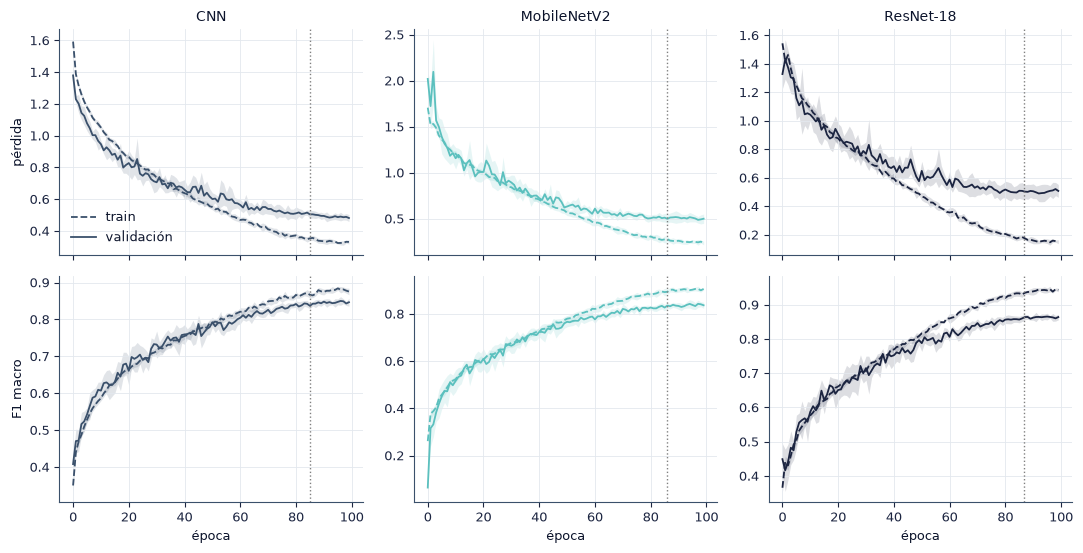

In [16]:
seeds = sorted(df["seed"].unique())
hist = {m: {s: load_pickle(C.run_dir(m, s) / "history.pkl") for s in seeds} for m in C.MODELS}

def banda(hs, key):
    L = max(len(h[key]) for h in hs)
    M = np.full((len(hs), L), np.nan)
    for i, h in enumerate(hs):
        M[i, :len(h[key])] = h[key]
    return np.nanmean(M, 0), np.nanstd(M, 0), (~np.isnan(M)).sum(0)

fig, axes = plt.subplots(2, 3, figsize=(11, 5.6), sharex="col")
fuente = {}
for j, m in enumerate(C.MODELS):
    hs = list(hist[m].values())
    best = np.mean([int(np.argmax(h["val_f1_macro"])) for h in hs])
    for i, (kt, kv, lab) in enumerate([("train_loss", "val_loss", "pérdida"), ("train_f1_macro", "val_f1_macro", "F1 macro")]):
        ax = axes[i, j]
        for k, ls, nom in ((kt, "--", "train"), (kv, "-", "validación")):
            mu, sd, n = banda(hs, k)
            ep = np.arange(len(mu))
            ax.plot(ep, mu, ls, color=P.color(m), label=nom, lw=1.3)
            ax.fill_between(ep, mu - sd, mu + sd, color=P.color(m), alpha=0.15, lw=0)
            fuente[(m, k)] = {"media": mu, "de": sd, "n_semillas": n}
        ax.axvline(best, color="grey", ls=":", lw=1)
        ax.set_ylabel(lab if j == 0 else "")
    axes[0, j].set_title(m)
    axes[1, j].set_xlabel("época")
axes[0, 0].legend()
fig.tight_layout()
P.save(fig, "5_1_curvas_aprendizaje", fuente)
plt.show()

In [17]:
brecha = []
for m in C.MODELS:
    for s, h in hist[m].items():
        b = int(np.argmax(h["val_f1_macro"]))
        brecha.append({"modelo": m, "semilla": s, "mejor época": b, "F1 train": h["train_f1_macro"][b],
                       "F1 val": h["val_f1_macro"][b], "brecha train − val": h["train_f1_macro"][b] - h["val_f1_macro"][b]})
brecha = pd.DataFrame(brecha)
res_brecha = brecha.groupby("modelo")[["mejor época", "F1 train", "F1 val", "brecha train − val"]].agg(["mean", "std"]).loc[C.MODELS]
save_pickle(brecha, C.SUMMARY / "brecha_train_val.pkl")
display(res_brecha.round(3))

mejor época         F1 train        F1 val         \
                   mean     std     mean    std   mean    std   
modelo                                                          
CNN              84.875  17.250    0.861  0.038  0.851  0.019   
MobileNetV2      85.875  10.629    0.887  0.023  0.848  0.014   
ResNet-18        86.750   9.254    0.938  0.013  0.873  0.007   

            brecha train − val         
                          mean    std  
modelo                                 
CNN                      0.011  0.024  
MobileNetV2              0.039  0.022  
ResNet-18                0.065  0.014

## Desempeño por clase

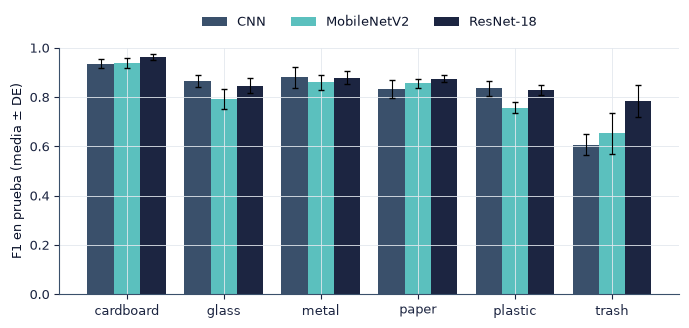

In [18]:
pc = []
for m in C.MODELS:
    for s in seeds:
        met = load_pickle(C.run_dir(m, s) / "metrics_test.pkl")
        for c, v in met["f1_per_class"].items():
            pc.append({"modelo": m, "semilla": s, "clase": c, "F1": v})
pc = pd.DataFrame(pc)
res_pc = pc.groupby(["clase", "modelo"])["F1"].agg(["mean", "std"]).unstack("modelo")
fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(C.CLASSES))
for i, m in enumerate(C.MODELS):
    mu = res_pc[("mean", m)].loc[C.CLASSES]
    sd = res_pc[("std", m)].loc[C.CLASSES]
    ax.bar(x + (i - 1) * 0.27, mu, 0.27, yerr=sd, color=P.color(m), label=m, capsize=2, error_kw={"lw": 0.8})
ax.set_xticks(x, C.CLASSES)
ax.set_ylabel("F1 en prueba (media ± DE)")
ax.set_ylim(0, 1)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.18))
P.save(fig, "5_1_f1_por_clase", pc)
plt.show()

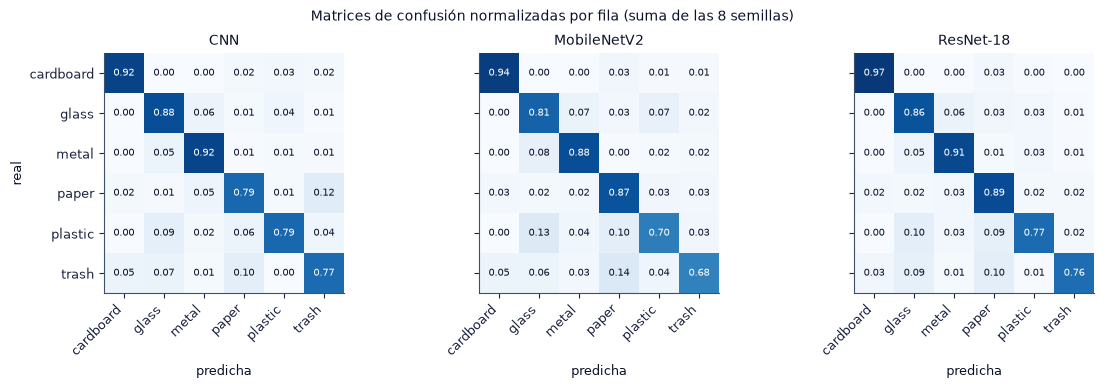

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
cms = {}
for ax, m in zip(axes, C.MODELS):
    cm = sum(load_pickle(C.run_dir(m, s) / "metrics_test.pkl")["confusion_matrix"] for s in seeds)
    cmn = cm / cm.sum(1, keepdims=True)
    cms[m] = cm
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(C.CLASSES)):
        for j in range(len(C.CLASSES)):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if cmn[i, j] > 0.6 else "#0B132B")
    ax.set_xticks(range(6), C.CLASSES, rotation=45, ha="right")
    ax.set_yticks(range(6), C.CLASSES if m == C.MODELS[0] else [""] * 6)
    ax.set_title(m)
    ax.set_xlabel("predicha")
    ax.grid(False)
axes[0].set_ylabel("real")
fig.suptitle(f"Matrices de confusión normalizadas por fila (suma de las {len(seeds)} semillas)", fontsize=10)
fig.tight_layout()
P.save(fig, "5_1_matrices_confusion", cms)
plt.show()

## Curvas ROC y precisión-recall

Para cada modelo usamos la semilla mediana, es decir, la semilla cuyo F1 macro en prueba es el más cercano a la mediana del modelo. Cada curva corresponde a una clase frente al resto.

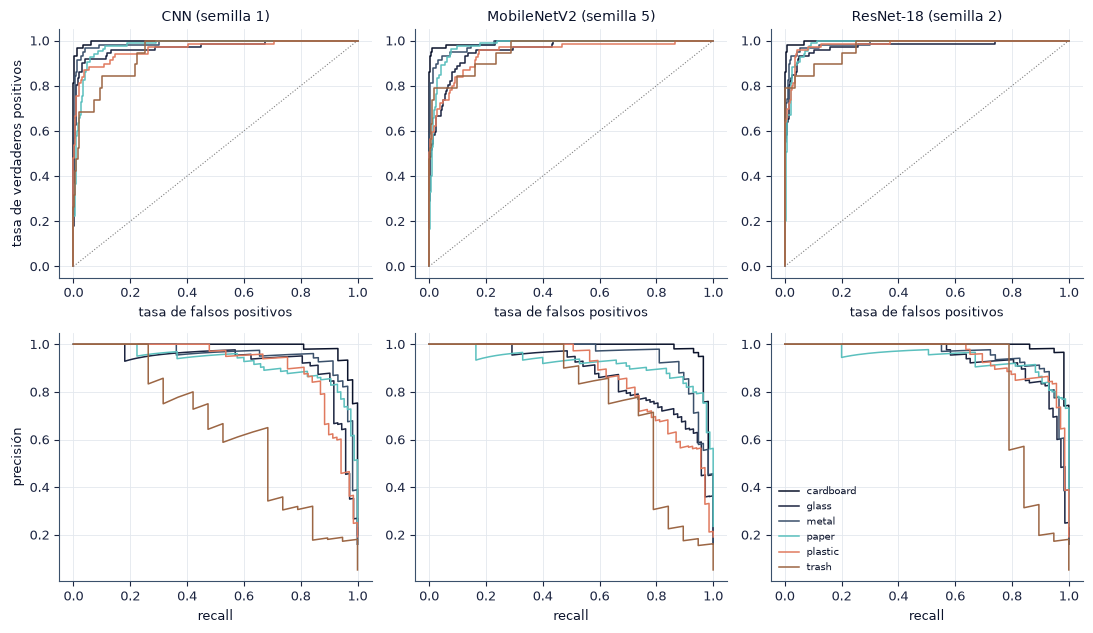

In [20]:
from sklearn.metrics import precision_recall_curve, roc_curve

def semilla_mediana(m):
    g = df[df["model"] == m].set_index("seed")["f1_macro"]
    return int((g - g.median()).abs().idxmin())

med = {m: semilla_mediana(m) for m in C.MODELS}
save_pickle(med, C.SUMMARY / "semilla_mediana.pkl")
colores = ["#0B132B", "#1C2541", "#3A506B", "#5BC0BE", "#E07A5F", "#9C6644"]
fig, axes = plt.subplots(2, 3, figsize=(11, 6.4))
curvas = {}
for j, m in enumerate(C.MODELS):
    p = load_pickle(C.run_dir(m, med[m]) / "test_predictions.pkl")
    for k, c in enumerate(C.CLASSES):
        yk = (p["y_true"] == k).astype(int)
        fpr, tpr, _ = roc_curve(yk, p["probs"][:, k])
        pr, rc, _ = precision_recall_curve(yk, p["probs"][:, k])
        axes[0, j].plot(fpr, tpr, color=colores[k], lw=1.1, label=c)
        axes[1, j].plot(rc, pr, color=colores[k], lw=1.1, label=c)
        curvas[(m, c)] = {"fpr": fpr, "tpr": tpr, "precision": pr, "recall": rc}
    axes[0, j].plot([0, 1], [0, 1], ":", color="grey", lw=0.8)
    axes[0, j].set_title(f"{m} (semilla {med[m]})")
    axes[0, j].set_xlabel("tasa de falsos positivos")
    axes[1, j].set_xlabel("recall")
axes[0, 0].set_ylabel("tasa de verdaderos positivos")
axes[1, 0].set_ylabel("precisión")
axes[1, 2].legend(fontsize=7, loc="lower left")
fig.tight_layout()
P.save(fig, "5_1_roc_pr", curvas)
plt.show()

## Calibración

El error de calibración esperado mide la diferencia entre la confianza del modelo y su acierto:

$$\text{ECE} = \sum_{b=1}^{15} \frac{n_b}{N}\,\big|\text{acc}_b - \text{conf}_b\big|,$$

con las predicciones agrupadas en 15 intervalos de confianza. En un modelo bien calibrado, las barras del diagrama de fiabilidad coinciden con la diagonal.

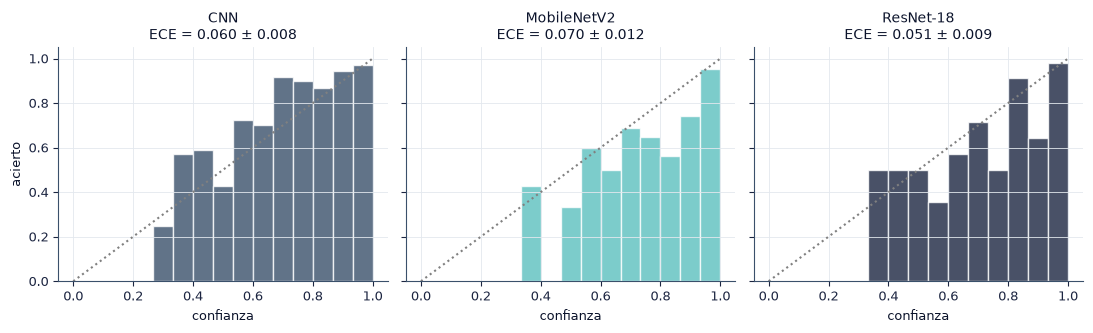

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
fiab = {}
for ax, m in zip(axes, C.MODELS):
    met = load_pickle(C.run_dir(m, med[m]) / "metrics_test.pkl")
    r = met["reliability"]
    centros = (r["edges"][:-1] + r["edges"][1:]) / 2
    ok = r["count"] > 0
    ax.bar(centros[ok], r["acc"][ok], width=1 / 15, color=P.color(m), alpha=0.8, edgecolor="white", label="acierto")
    ax.plot([0, 1], [0, 1], ":", color="grey")
    ece = df[df["model"] == m]["ece"]
    ax.set_title(f"{m}\nECE = {ece.mean():.3f} ± {ece.std():.3f}")
    ax.set_xlabel("confianza")
    fiab[m] = r
axes[0].set_ylabel("acierto")
fig.tight_layout()
P.save(fig, "5_1_fiabilidad", fiab)
plt.show()

## Descomposición de la varianza

Mediante un ANOVA de un factor (modelo), con las semillas como réplicas, estimamos qué proporción de la variación del F1 macro se debe a la arquitectura ($\eta^2 = SS_{entre}/SS_{total}$) y la correlación intraclase ICC(1). El análisis pareado por semilla se presenta en la sección 5.2.

,valor
F,11.4989
p,0.0004
eta²,0.5227
ICC(1),0.5675
gl,"(2, 21)"


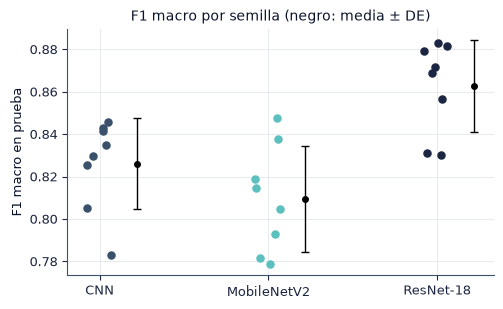

In [22]:
from src.stats import variance_decomposition

vd = variance_decomposition(df)
save_pickle(vd, C.SUMMARY / "descomposicion_varianza.pkl")
display(pd.Series({"F": vd["F"], "p": vd["p"], "eta²": vd["eta2"], "ICC(1)": vd["icc1"],
                   "gl": str(vd["gl"])}, dtype=object).to_frame("valor"))

fig, ax = plt.subplots(figsize=(5.5, 3.2))
rng = np.random.default_rng(0)
for i, m in enumerate(C.MODELS):
    v = df[df["model"] == m]["f1_macro"].to_numpy()
    ax.scatter(i + rng.uniform(-0.08, 0.08, len(v)), v, color=P.color(m), s=26, zorder=2)
    ax.errorbar(i + 0.22, v.mean(), yerr=v.std(ddof=1), fmt="o", color="black", ms=4, capsize=3, lw=1)
ax.set_xticks(range(3), C.MODELS)
ax.set_ylabel("F1 macro en prueba")
ax.set_title("F1 macro por semilla (negro: media ± DE)")
P.save(fig, "5_1_f1_por_semilla", df[["model", "seed", "f1_macro"]])
plt.show()

## Desempeño frente a costo

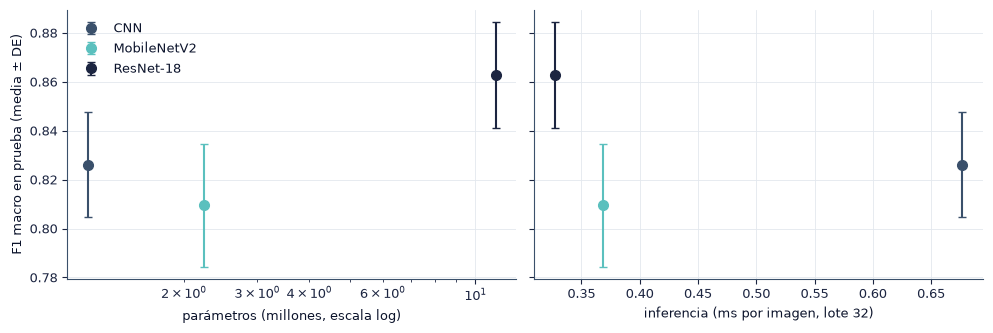

In [23]:
res = df.groupby("model").agg(f1=("f1_macro", "mean"), f1_sd=("f1_macro", "std"), params=("params", "first"),
                               ms=("ms_per_image", "mean"), ms_sd=("ms_per_image", "std")).loc[C.MODELS]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for m, r in res.iterrows():
    axes[0].errorbar(r["params"] / 1e6, r["f1"], yerr=r["f1_sd"], fmt="o", color=P.color(m), capsize=3, ms=7, label=m)
    axes[1].errorbar(r["ms"], r["f1"], xerr=r["ms_sd"], yerr=r["f1_sd"], fmt="o", color=P.color(m), capsize=3, ms=7)
axes[0].set_xscale("log")
axes[0].set_xlabel("parámetros (millones, escala log)")
axes[1].set_xlabel("inferencia (ms por imagen, lote 32)")
axes[0].set_ylabel("F1 macro en prueba (media ± DE)")
axes[0].legend()
fig.tight_layout()
P.save(fig, "5_1_tradeoff", res)
plt.show()

In [24]:
orden = df.groupby("model")["f1_macro"].mean().sort_values(ascending=False)
mejor, peor = orden.index[0], orden.index[-1]
gap = res_brecha["brecha train − val"]["mean"]
txt = [f"**Síntesis.** {mejor} obtiene el mayor F1 macro medio en prueba ({orden.iloc[0]:.3f}) y {peor} el menor "
       f"({orden.iloc[-1]:.3f}); la diferencia es {orden.iloc[0] - orden.iloc[-1]:.3f}.",
       f"La arquitectura explica el {100 * vd['eta2']:.0f} % de la varianza del F1 macro entre corridas.",
       f"La clase con menor F1 promedio es `{pc.groupby('clase')['F1'].mean().idxmin()}`.",
       f"La mayor brecha train − val en la mejor época la tiene {gap.idxmax()} ({gap.max():.3f})."]
display(Markdown(" ".join(txt)))

**Síntesis.** ResNet-18 obtiene el mayor F1 macro medio en prueba (0.863) y MobileNetV2 el menor (0.809); la diferencia es 0.053. La arquitectura explica el 52 % de la varianza del F1 macro entre corridas. La clase con menor F1 promedio es `trash`. La mayor brecha train − val en la mejor época la tiene ResNet-18 (0.065).

## Conclusión

La Tabla 5.1 resume el desempeño de los tres modelos con su variación entre semillas, y las figuras muestran la distribución de los errores por clase, la calibración y el costo de cada modelo. La significancia y la relevancia práctica de las diferencias se evalúan en la sección 5.2.